# 08 — Comparação entre as bases, recomendações e limitações

**CRISP-DM, fases 5 e 6** · corresponde às seções **§8, §9 e §10** de `docs/DOCUMENTACAO.md`

Os notebooks 04 a 07 responderam cada pergunta **separadamente** em cada base. Aqui:
1. Pareamos as atividades equivalentes das duas plataformas
2. Aplicamos a regra de **convergência** (que considera tamanho do efeito **e** significância)
3. Montamos a tabela comparativa
4. Transformamos os resultados em **recomendações proporcionais à evidência** para o Beready
5. Registramos as limitações

In [1]:
import sys, json, warnings
from pathlib import Path

# encontra a raiz do projeto (pasta que contém src/config.py), venha o notebook de onde vier
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

import config as C
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Projeto:", ROOT)
R_A = json.loads((C.TAB / "ares_resultados.json").read_text(encoding="utf-8"))
R_E = json.loads((C.TAB / "ednet_resultados.json").read_text(encoding="utf-8"))

Projeto: C:\Users\braia\OneDrive\Documentos\GitHub\Datasets-Beready


## 1. Atividades equivalentes

As duas plataformas são diferentes. Para comparar, pareamos as atividades pela **mesma função pedagógica**:

In [2]:
from comparacao import EQUIV, METRICS
pd.DataFrame(EQUIV, columns=["função pedagógica", "ARES", "EdNet"])

,função pedagógica,ARES,EdNet
0,Responder questões,Responder questões/tarefas,Prática por parte (sprint)
1,Ver feedback/explicação,Visualização de feedback/nota,Leitura de explicações (feedback)
2,Estudar conteúdo,Leitura de textos,Aulas (vídeo/texto)
3,Recursos de apoio/revisão,Vocabulário (palavras e traduções),Caderno de erros/anotações
4,Atividade de entrada,Tutorial,Diagnóstico inicial


## 2. Regra de convergência

Um efeito só “conta” quando **|ρ| ≥ 0,1 E p < 0,05**. Nas perguntas com 10 atividades (Q4, Q10), o p do ARES é o corrigido por Holm. Assim, um valor grande porém não significativo no ARES, ou significativo porém desprezível no EdNet, **não** conta como efeito.

- **Convergente:** o mesmo sinal nas duas bases (+/+, −/− ou 0/0)
- **Parcialmente convergente:** efeito numa base e não na outra
- **Divergente:** sinais opostos

In [3]:
import inspect
from comparacao import concl
print(inspect.getsource(concl))

def concl(ra, re_, pa, pe, lim=0.1):
    """Efeito = |ρ| ≥ 0,1 E p < 0,05 (p já corrigido por Holm quando há várias atividades)."""
    sinal = lambda r, p: "0" if abs(r) < lim or p >= 0.05 else "+" if r > 0 else "−"
    sa, se = sinal(ra, pa), sinal(re_, pe)
    if sa == se == "0":
        return "Convergente (sem efeito nas duas)"
    return "Convergente" if sa == se else "Parcialmente convergente" if "0" in (sa, se) else "Divergente"



## 3. Tabela comparativa

In [4]:
linhas = []
for q, chave in (("Q1", "correlacoes"), ("Q5", "correlacoes_evolucao")):
    for nome, ma, me in METRICS:
        ra, re_ = R_A[q][chave][ma], R_E[q][chave][me]
        linhas.append((q, nome, ra["rho"], ra["p"], re_["rho"], re_["p"], concl(ra["rho"], re_["rho"], ra["p"], re_["p"])))
a4 = {r["atividade"]: r for r in R_A["Q4"]["atividades"]}; e4 = {r["atividade"]: r for r in R_E["Q4"]["atividades"]}
a10 = {r["atividade"]: r for r in R_A["Q10"]["atividades"]}; e10 = {r["atividade"]: r for r in R_E["Q10"]["atividades"]}
for funcao, aa, ee in EQUIV:
    linhas.append(("Q4", funcao, a4[aa]["rho_corrigido"], a4[aa]["p_corrigido_holm"], e4[ee]["rho_corrigido"], e4[ee]["p_corrigido_holm"],
                   concl(a4[aa]["rho_corrigido"], e4[ee]["rho_corrigido"], a4[aa]["p_corrigido_holm"], e4[ee]["p_corrigido_holm"])))
for funcao, aa, ee in EQUIV:
    linhas.append(("Q10", funcao, a10[aa]["rho_parcial_nota_pos_ctrl_pre"], a10[aa]["p_parcial_holm"],
                   e10[ee]["rho_parcial_acuracia_ctrl_diag"], e10[ee]["p_parcial"],
                   concl(a10[aa]["rho_parcial_nota_pos_ctrl_pre"], e10[ee]["rho_parcial_acuracia_ctrl_diag"],
                         a10[aa]["p_parcial_holm"], e10[ee]["p_parcial"])))
comp = pd.DataFrame(linhas, columns=["pergunta", "medida", "ARES ρ", "ARES p", "EdNet ρ", "EdNet p", "conclusão"])
comp["ARES p"] = comp["ARES p"].map(lambda p: f"{p:.3f}")
comp["EdNet p"] = comp["EdNet p"].map(lambda p: f"{p:.1e}")
comp.round(3)

,pergunta,medida,ARES ρ,ARES p,EdNet ρ,EdNet p,conclusão
0,Q1,Nº de interações,0.079,0.352,0.149,0.0e+00,Parcialmente convergente
1,Q1,Nº de sessões,0.082,0.335,0.083,1.5e-115,Convergente (sem efeito nas duas)
2,Q1,Dias ativos,0.037,0.663,0.070,1.4e-83,Convergente (sem efeito nas duas)
3,Q5,Nº de interações,0.001,0.991,0.039,4.4e-16,Convergente (sem efeito nas duas)
4,Q5,Nº de sessões,0.030,0.723,0.023,1.5e-06,Convergente (sem efeito nas duas)
5,Q5,Dias ativos,0.009,0.915,0.022,4.0e-06,Convergente (sem efeito nas duas)
6,Q4,Responder questões,-0.024,1.000,-0.109,1.1e-291,Parcialmente convergente
7,Q4,Ver feedback/explicação,0.141,0.366,0.062,4.5e-96,Convergente (sem efeito nas duas)
8,Q4,Estudar conteúdo,0.314,0.000,0.244,0.0e+00,Convergente
9,Q4,Recursos de apoio/revisão,-0.092,1.000,0.174,0.0e+00,Parcialmente convergente


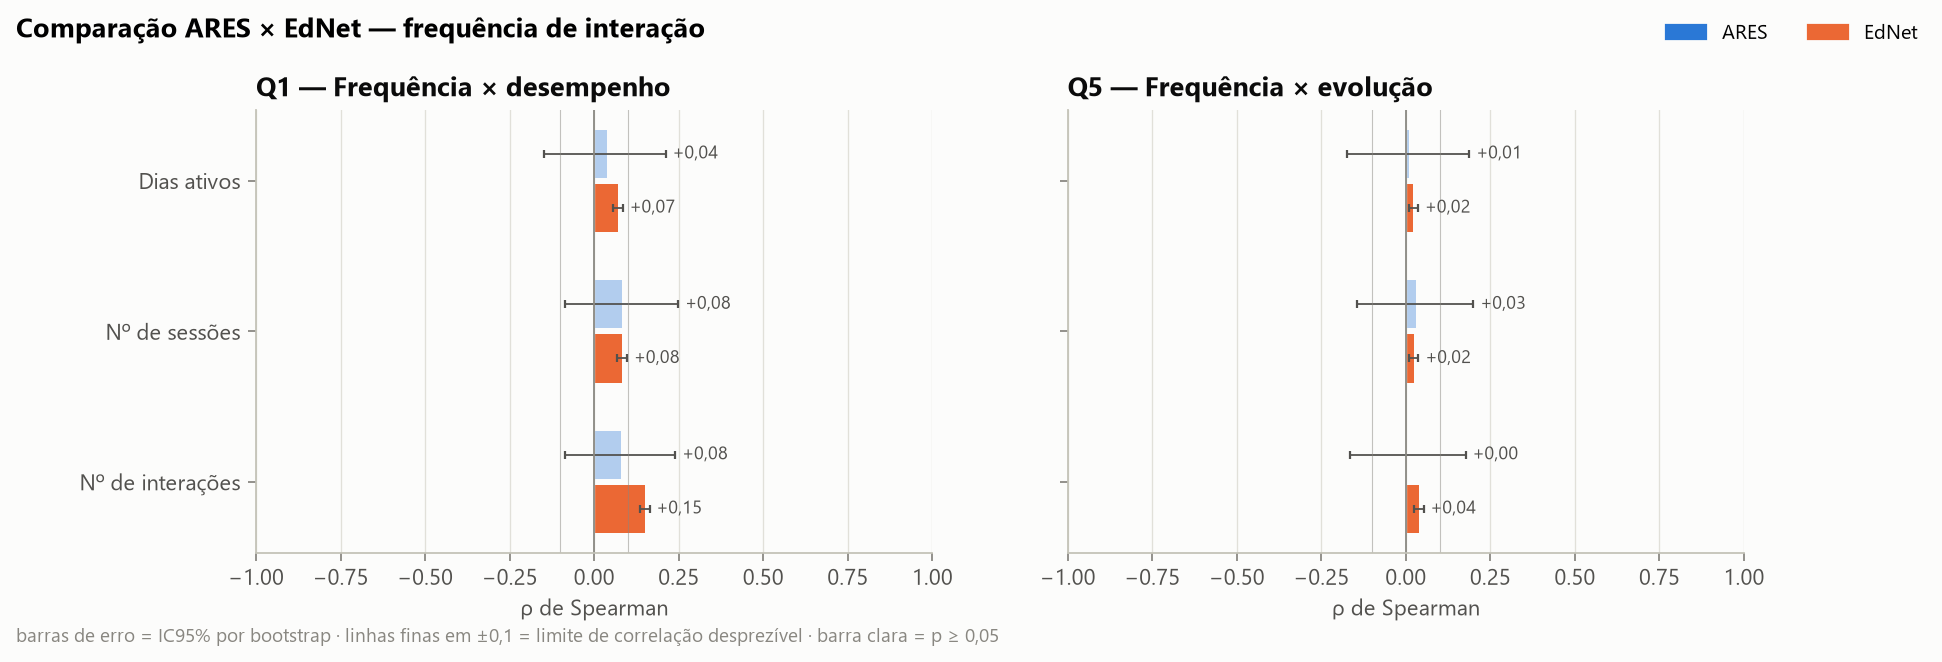

In [5]:
Image(filename=str(C.FIG / "comparacao" / "Q1_Q5_comparacao.png"))

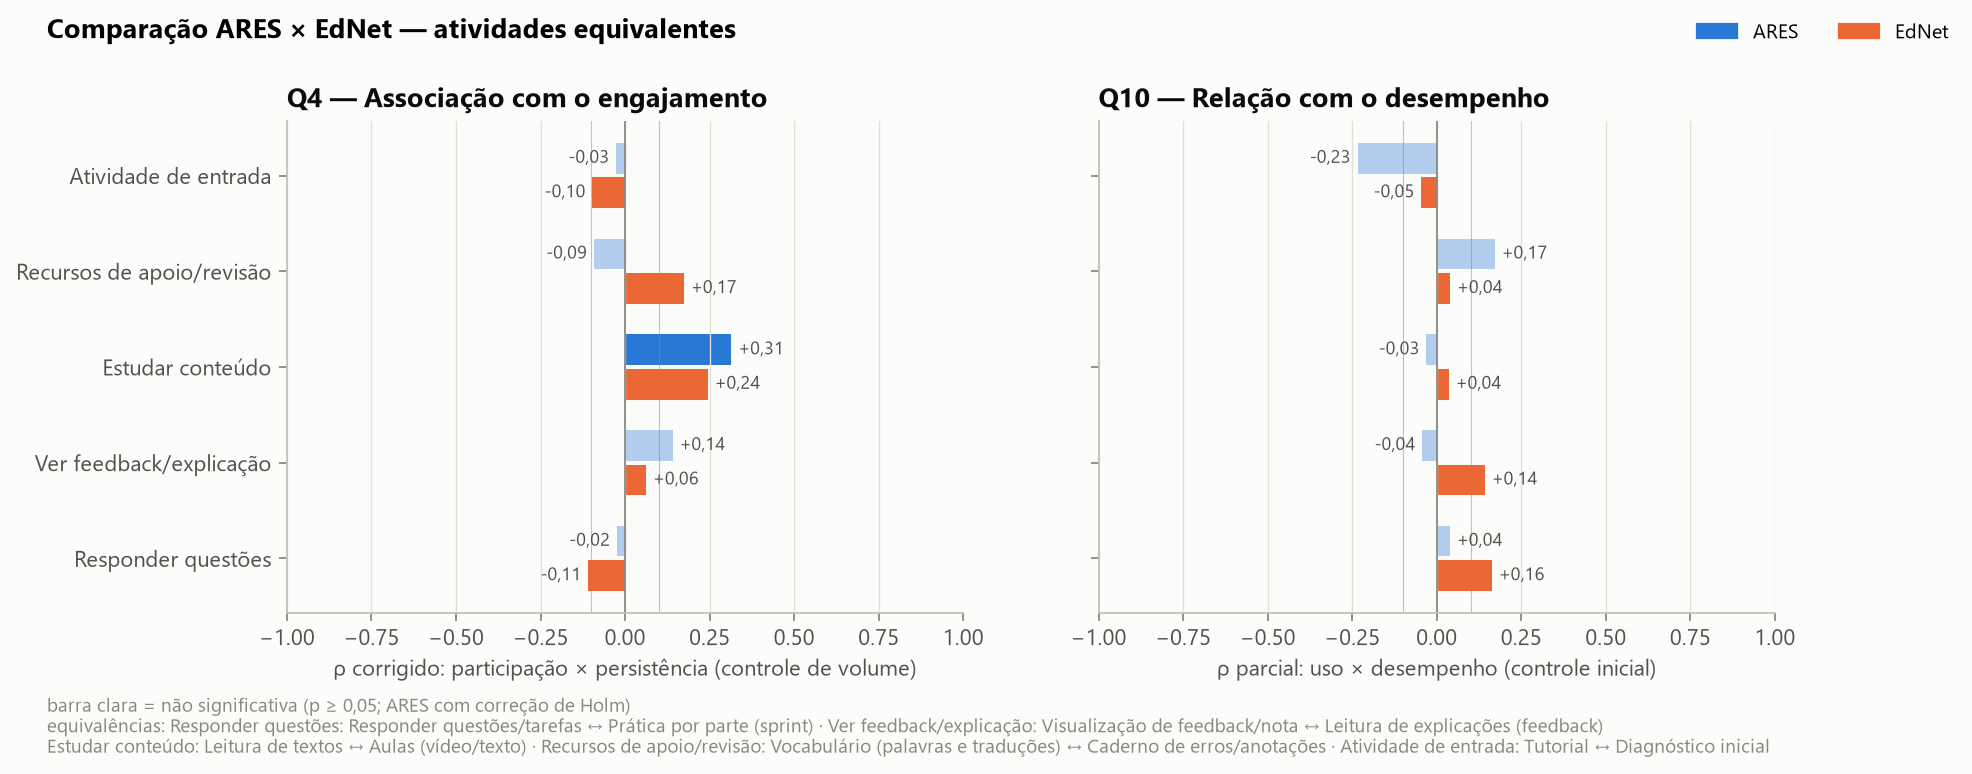

In [6]:
Image(filename=str(C.FIG / "comparacao" / "Q4_Q10_comparacao.png"))

### Interpretação

1. **Nenhum resultado é divergente.** Quando as bases discordam, o efeito aparece no EdNet e não no ARES, nunca em sentidos opostos. Parte disso é tamanho de amostra: o EdNet detecta efeitos que o ARES (n = 141) não teria como detectar.
2. **Q5 é a conclusão mais robusta:** com fórmulas, escalas e tamanhos diferentes, não há associação relevante entre interagir mais e evoluir mais.
3. **Q1 difere pouco:** EdNet 0,15 (fraco) × ARES 0,08 (não detectado, compatível com um efeito fraco).
4. **Q4 converge em um ponto:** dedicar mais do uso a **conteúdo de estudo** está associado a voltar mais vezes, nas duas bases.
5. **Q10:** a relação das atividades com o desempenho é fraca ou inexistente nas duas bases.

## 4. Recomendações para o Beready (§9)

> Nenhuma análise mostra que uma interação **causa** melhor aprendizagem ou engajamento. As recomendações estão agrupadas pela **origem da evidência** e são **hipóteses a testar** (de preferência com teste A/B).

**A. Apoiadas em associação observada nas duas bases**

| # | Recomendação (hipótese) | Evidência | Força |
|---|---|---|---|
| 1 | Não usar volume de cliques ou tempo de tela como meta de sucesso; medir aprendizagem (pré/pós) | Q1 fraca/não detectada; Q5 desprezível nas duas bases | Moderada |
| 2 | Dar destaque ao conteúdo de estudo (textos, aulas) | Q4: +0,31 (ARES) e +0,24 (EdNet) | Fraca a moderada |

**B. Apoiadas em observação descritiva**

| # | Recomendação | Evidência |
|---|---|---|
| 3 | Atacar o abandono logo após a atividade de entrada | 62,5% dos estudantes do EdNet não passaram do diagnóstico |
| 4 | Instrumentar o Beready (log xAPI + pré/pós-avaliação) | Foi o que permitiu responder Q1/Q5 no ARES |

**C. Hipóteses exploratórias (investigar antes de priorizar)**

| # | Hipótese | Por que é fraca |
|---|---|---|
| 5 | Recursos de revisão ajudam a reter alunos | Só uma base (EdNet), associação fraca |
| 6 | Reabrir o tutorial muitas vezes indica dificuldade | p ajustado no limite (0,054) |

**Retiradas na revisão** (não se sustentaram nos resultados corrigidos): “feedback aumenta o engajamento”, “recomendação adaptativa aumenta o engajamento”, “cuidar do mobile”, “vocabulário melhora o desempenho”.

## 5. Limitações (§10)

- **Correlação não é causalidade.** Todos os resultados são associações observacionais.
- **ARES pequeno (n = 141):** só detecta |ρ| ≥ 0,24; “não detectado” ≠ “não existe”.
- **EdNet sem pré/pós-teste:** o diagnóstico serve de *proxy*, e as questões são adaptativas.
- **Q5 do EdNet com viés de seleção:** só entram estudantes com ≥ 40 questões de prática.
- **Na base grande, p-valores não informam:** a leitura é pela magnitude.
- **Múltiplos testes:** corrigidos por Holm no ARES.
- **Categorias de atividade do ARES** foram definidas por regras sobre os descritores.
- **Populações diferentes:** leitura em inglês (ARES) × TOEIC na Coreia (EdNet).

In [7]:
oficial = json.loads((C.TAB / "comparacao.json").read_text(encoding="utf-8"))
conc_oficial = [r["conclusao"] for q in ("Q1", "Q5", "Q4", "Q10") for r in oficial[q]]
assert conc_oficial == comp["conclusão"].tolist()
print(f"✅ As {len(conc_oficial)} conclusões da tabela conferem com outputs/tables/comparacao.json (e com a §8 da documentação).")

✅ As 16 conclusões da tabela conferem com outputs/tables/comparacao.json (e com a §8 da documentação).


**Próximo:** `09_auditoria.ipynb`.